# Project 2: choosing and understanding the word embedding model

Task: SNLI natural language inference (premise + hypothesis -> entailment / neutral / contradiction).

1. **Choosing an embedding model**: dataset and language, candidate models, tokenisation coherence, vocabulary coverage, decision.
2. **What the model captures**: neighbours, word relations, geometry, task-specific evidence, limitations.
3. **Additional dataset checks** that affect how we read the results (lexical overlap, negation).

## Setup

In [1]:
import warnings

warnings.filterwarnings("ignore")

import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score
from transformers import AutoTokenizer

# Add the parent directory of project to Python's path
root = Path.cwd().parent
sys.path.insert(0, str(root))

from src.data_analysis import (
    has_negation,
    lexical_overlap,
    load_input_embeddings,
    nearest_neighbours,
    pair_cosines,
    pair_similarities,
    pca_2d,
    pieces_per_word,
    probe_nli,
    random_pair_similarity,
    report_tokenizer_coverage,
    shallow_baseline,
    token_stats,
    word_vector,
)
from src.dataset import LABEL_NAMES, convert_to_dataframe, load_snli_dataset
from src.plots import (
    plot_coverage,
    plot_distribution_by_label,
    plot_label_counts,
    plot_length_distributions,
    plot_norm_vs_frequency,
    plot_pair_similarities,
    plot_pieces_per_word,
    plot_probe,
    plot_relation_summary,
    plot_word_maps,
)

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print("device:", DEVICE)

device: cpu


In [2]:
# settings
premise_col = "premise"
hypothesis_col = "hypothesis"
label_col = "label"
max_length = 128  # max length for tokenization (tuned per system)
SAMPLE = 100_000  # training pairs used for the token statistics and plots
RECOMPUTE_DIAGNOSTICS = False  # full-corpus tokenizer pass is slow; JSON files are cached
SEED = 0
out_dir = Path("output")
fig_dir = out_dir / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

EmbeddingModels = [
    "sentence-transformers/paraphrase-MiniLM-L3-v2",
    "sentence-transformers/all-mpnet-base-v2",
    "sentence-transformers/nli-mpnet-base-v2",
]
short = {m: m.split("/")[-1] for m in EmbeddingModels}
mpnet = EmbeddingModels[1]

train_df, val_df, test_df = convert_to_dataframe(load_snli_dataset())
needed = [premise_col, hypothesis_col, label_col]
missing = [col for col in needed if col not in train_df.columns]
if missing:
    raise ValueError(f"Dataset is missing columns: {missing}")
train_df = train_df[needed].dropna().copy()
sample_df = train_df.sample(SAMPLE, random_state=SEED)

tokenizers = {m: AutoTokenizer.from_pretrained(m) for m in EmbeddingModels}
tables = {m: load_input_embeddings(m) for m in EmbeddingModels}
print(f"train: {len(train_df)} | validation: {len(val_df)} | test: {len(test_df)}")

W1114 14:37:03.357000 12200 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 55/55 [00:00<00:00, 3639.05it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   4%|▍         | 8/199 [00:00<00:02, 75.50it/s]

Loading weights:  16%|█▌        | 32/199 [00:00<00:01, 160.51it/s]

... (11 outputs left out)

Loading weights:  38%|███▊      | 75/199 [00:00<00:01, 118.11it/s]

Loading weights:  50%|█████     | 100/199 [00:00<00:00, 156.80it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 275.44it/s]

train: 549367 | validation: 9842 | test: 9824


# 1. Choosing a word embedding model

## 1.1 Dataset and language

SNLI premises are English image captions, and hypotheses are short sentences written by crowd workers. The text is everyday, concrete vocabulary (people, animals, clothing, places, actions), so general-purpose English embeddings should fit. Labels are balanced by construction.

,premise words (mean),hypothesis words (mean)
count,549367.00,549367.00
mean,12.85,7.42
std,5.66,3.07
min,2.00,1.00
25%,9.00,5.00
50%,12.00,7.00
75%,16.00,9.00
max,78.00,56.00


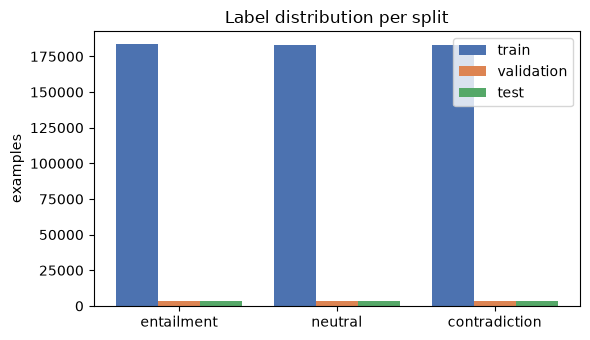

In [3]:
plot_label_counts(
    {"train": train_df, "validation": val_df, "test": test_df},
    LABEL_NAMES,
    fig_dir / "label_counts.png",
)
pd.DataFrame(
    {
        "premise words (mean)": train_df[premise_col].str.split().str.len().describe(),
        "hypothesis words (mean)": train_df[hypothesis_col].str.split().str.len().describe(),
    }
).round(2)

## 1.2 Candidate models

- `paraphrase-MiniLM-L3-v2`: small (384d), BERT WordPiece vocabulary, trained on paraphrase data.
- `all-mpnet-base-v2`: 768d, MPNet vocabulary, trained on 1B+ sentence pairs.
- `nli-mpnet-base-v2`: 768d, same MPNet vocabulary, fine-tuned on NLI data (SNLI/MultiNLI), the same task family as our dataset.

The MPNet vocabulary contains the same 30,522 WordPiece strings as the BERT one plus 5 special tokens (the check below counts the overlap), so all three segment text identically but index it with different ids.

In [4]:
probe_text = ["A Man", "a man"]
pd.DataFrame(
    {
        short[m]: {
            "tokenizer": tokenizers[m].__class__.__name__,
            "vocabulary size": len(tokenizers[m].get_vocab()),
            "wordpieces shared with all-mpnet": len(
                set(tokenizers[m].get_vocab()) & set(tokenizers[mpnet].get_vocab())
            ),
            "embedding dim": tables[m].shape[1],
            "lower-cases input": tokenizers[m].tokenize(probe_text[0])
            == tokenizers[m].tokenize(probe_text[1]),
            "unknown token": tokenizers[m].unk_token,
        }
        for m in EmbeddingModels
    }
).T

,tokenizer,vocabulary size,wordpieces shared with all-mpnet,embedding dim,lower-cases input,unknown token
paraphrase-MiniLM-L3-v2,BertTokenizer,30522,30522,384,True,[UNK]
all-mpnet-base-v2,MPNetTokenizer,30527,30527,768,True,[UNK]
nli-mpnet-base-v2,MPNetTokenizer,30527,30527,768,True,[UNK]


## 1.3 Is our tokenisation coherent with the model's definition of a token?

The embedding tables are indexed by **subword pieces** (WordPiece-style vocabularies), not words. We therefore always tokenise with the model's own tokenizer, so every token we feed in has an embedding row. We check (a) example tokenisations, and (b) how strongly words get fragmented.

In [5]:
examples = [
    "A man is sleeping outdoors with his dog.",
    "Two kayakers paddle past a pagoda in Vietnam.",
    "Nobody isn't wearing a sweatshirt.",
]
for text in examples:
    print(text)
    for m in EmbeddingModels:
        print(f"  {short[m]:26s}", tokenizers[m].tokenize(text))

A man is sleeping outdoors with his dog.
  paraphrase-MiniLM-L3-v2    ['a', 'man', 'is', 'sleeping', 'outdoors', 'with', 'his', 'dog', '.']
  all-mpnet-base-v2          ['a', 'man', 'is', 'sleeping', 'outdoors', 'with', 'his', 'dog', '.']
  nli-mpnet-base-v2          ['a', 'man', 'is', 'sleeping', 'outdoors', 'with', 'his', 'dog', '.']
Two kayakers paddle past a pagoda in Vietnam.
  paraphrase-MiniLM-L3-v2    ['two', 'kay', '##aker', '##s', 'paddle', 'past', 'a', 'pagoda', 'in', 'vietnam', '.']
  all-mpnet-base-v2          ['two', 'kay', '##aker', '##s', 'paddle', 'past', 'a', 'pagoda', 'in', 'vietnam', '.']
  nli-mpnet-base-v2          ['two', 'kay', '##aker', '##s', 'paddle', 'past', 'a', 'pagoda', 'in', 'vietnam', '.']
Nobody isn't wearing a sweatshirt.
  paraphrase-MiniLM-L3-v2    ['nobody', 'isn', "'", 't', 'wearing', 'a', 'sweatshirt', '.']
  all-mpnet-base-v2          ['nobody', 'isn', "'", 't', 'wearing', 'a', 'sweatshirt', '.']
  nli-mpnet-base-v2          ['nobody', 'isn', "'

identical segmentation of every word in all three tokenizers: True


unique words                          19447.000
mean pieces per unique word               1.622
unique words split into 2+ pieces         0.439
running words split into 2+ pieces        0.026
dtype: float64

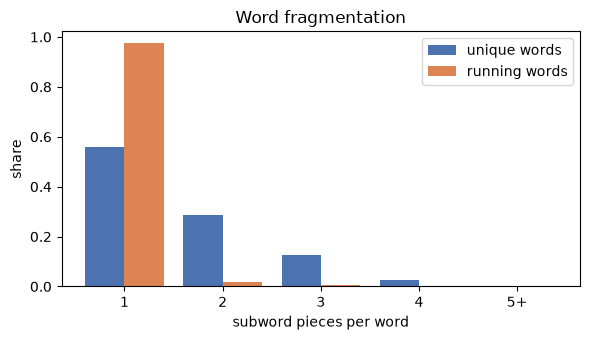

In [6]:
all_text = pd.concat([sample_df[premise_col], sample_df[hypothesis_col]]).tolist()
per_model = {m: pieces_per_word(all_text, tokenizers[m]) for m in EmbeddingModels}
identical = all(
    np.array_equal(per_model[m][0], per_model[EmbeddingModels[0]][0])
    for m in EmbeddingModels
)
print("identical segmentation of every word in all three tokenizers:", identical)
pieces, freq = per_model[EmbeddingModels[0]]
plot_pieces_per_word(pieces, freq, path=fig_dir / "pieces_per_word.png")
pd.Series(
    {
        "unique words": len(pieces),
        "mean pieces per unique word": pieces.mean(),
        "unique words split into 2+ pieces": (pieces > 1).mean(),
        "running words split into 2+ pieces": freq[pieces > 1].sum() / freq.sum(),
    }
).round(3)

## 1.4 Does the vocabulary cover our texts?

Full-corpus diagnostics (every premise and hypothesis of the training set) are cached in `output/tokenizer_diagnostics_*.json`; set `RECOMPUTE_DIAGNOSTICS = True` to regenerate them.

In [7]:
def diagnostics_path(model):
    return out_dir / f"tokenizer_diagnostics_{model.replace('/', '_')}.json"


parts = {
    "premise": train_df[premise_col].astype(str).tolist(),
    "hypothesis": train_df[hypothesis_col].astype(str).tolist(),
}
for model in EmbeddingModels:
    path = diagnostics_path(model)
    if path.exists() and not RECOMPUTE_DIAGNOSTICS:
        continue
    coverage = {
        part: report_tokenizer_coverage(texts, tokenizers[model], max_length, model)
        for part, texts in parts.items()
    }
    path.write_text(json.dumps(coverage, indent=2))
    print(f"saved {path}")

rows = []
for model in EmbeddingModels:
    for part, d in json.loads(diagnostics_path(model).read_text()).items():
        rows.append(
            {
                "model": short[model],
                "text": part,
                "unknown piece rate": d["unknown_subword_rate"],
                "unique forms": d["unique_whitespace_forms"],
                "forms with [UNK]": d["unique_whitespace_forms_containing_unk_rate"],
                "pieces / form": d["mean_subword_pieces_per_whitespace_form"],
                f"longer than {max_length}": d["documents_longer_than_max_length_rate"],
            }
        )
pd.DataFrame(rows).set_index(["model", "text"]).round(4)

unknown piece rate  unique forms  \
model                   text                                           
paraphrase-MiniLM-L3-v2 premise                    0.0         33923   
                        hypothesis                 0.0         52499   
all-mpnet-base-v2       premise                    0.0         33923   
                        hypothesis                 0.0         52499   
nli-mpnet-base-v2       premise                    0.0         33923   
                        hypothesis                 0.0         52499   

                                    forms with [UNK]  pieces / form  \
model                   text                                          
paraphrase-MiniLM-L3-v2 premise                  0.0         2.0014   
                        hypothesis               0.0         2.1137   
all-mpnet-base-v2       premise                  0.0         2.0014   
                        hypothesis               0.0         2.1137   
nli-mpnet-base-v2       premise                  0.0         2.0014   
                        hypothesis               0.0         2.1137   

                                    longer than 128  
model                   text                         
paraphrase-MiniLM-L3-v2 premise                 0.0  
                        hypothesis              0.0  
all-mpnet-base-v2       premise                 0.0  
                        hypothesis              0.0  
nli-mpnet-base-v2       premise                 0.0  
                        hypothesis              0.0

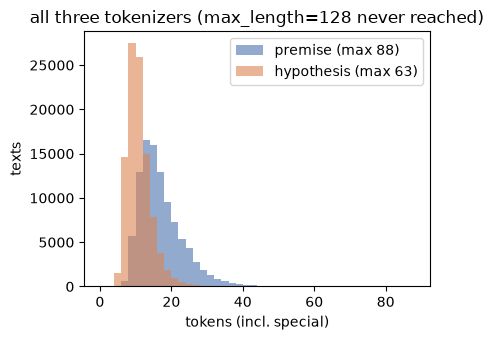

In [8]:
# Token statistics on a training sample: lengths and how much of the vocabulary is used
stats = {}
for m in EmbeddingModels:
    vocab = tables[m].shape[0]
    stats[m] = {
        part: token_stats(sample_df[col].astype(str), tokenizers[m], vocab)
        for part, col in [("premise", premise_col), ("hypothesis", hypothesis_col)]
    }
counts = {
    m: stats[m]["premise"][1] + stats[m]["hypothesis"][1] for m in EmbeddingModels
}

plot_length_distributions(
    {"all three tokenizers": {part: stats[mpnet][part][0] for part in ("premise", "hypothesis")}},
    max_length,
    fig_dir / "token_lengths.png",
)

,vocabulary entries used,share of vocabulary used,entries covering 90% of tokens,tokens seen < 10 times (of used)
paraphrase-MiniLM-L3-v2,14107.0,0.462,906.0,0.566
all-mpnet-base-v2,14107.0,0.462,906.0,0.566
nli-mpnet-base-v2,14107.0,0.462,906.0,0.566


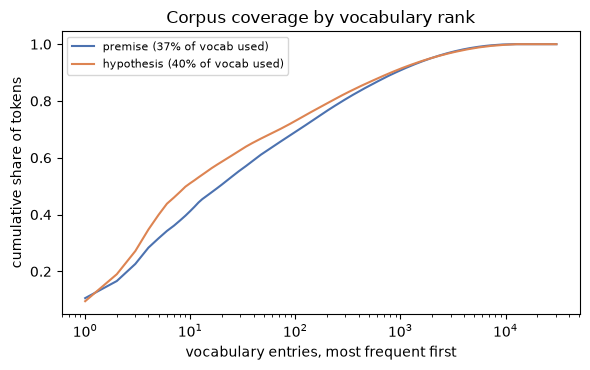

In [9]:
plot_coverage(
    {"premise": stats[mpnet]["premise"][1], "hypothesis": stats[mpnet]["hypothesis"][1]},
    fig_dir / "coverage.png",
)
pd.DataFrame(
    {
        short[m]: {
            "vocabulary entries used": int((counts[m] > 0).sum()),
            "share of vocabulary used": (counts[m] > 0).mean(),
            "entries covering 90% of tokens": int(
                np.searchsorted(np.cumsum(np.sort(counts[m])[::-1]) / counts[m].sum(), 0.9) + 1
            ),
            "tokens seen < 10 times (of used)": ((counts[m] > 0) & (counts[m] < 10)).sum()
            / (counts[m] > 0).sum(),
        }
        for m in EmbeddingModels
    }
).T.round(3)

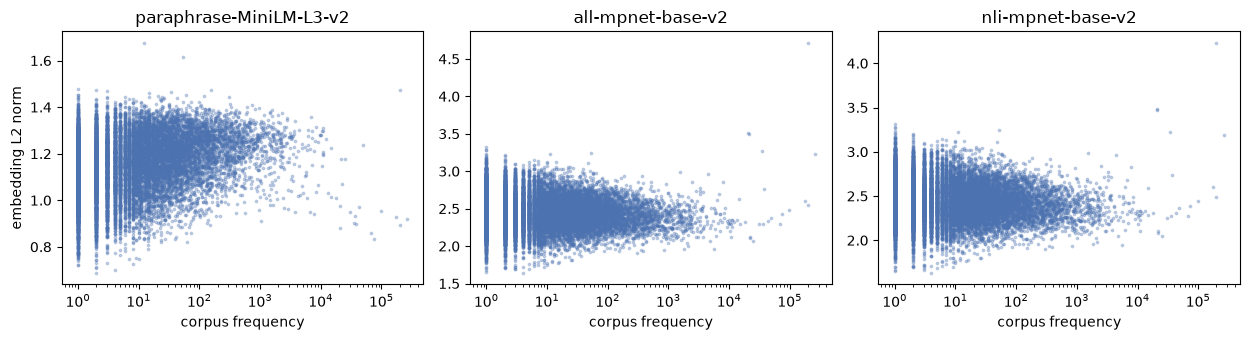

In [10]:
# Rarely seen vocabulary entries are the ones whose pretrained vector we can least rely on in this domain
plot_norm_vs_frequency(
    {short[m]: tables[m] for m in EmbeddingModels},
    {short[m]: counts[m] for m in EmbeddingModels},
    fig_dir / "norm_vs_frequency.png",
)

## 1.5 Decision

- **Language / domain fit:** all three models are English, general-purpose, lower-casing WordPiece models. SNLI is plain English captions, and every text tokenises without a single `[UNK]` (0.0 unknown-piece rate in premises and hypotheses over all 549k training pairs).
- **Tokenisation coherence:** we use each model's own tokenizer, so tokens are exactly its embedding rows. Only 2.6% of running words are split into several pieces, but 43.9% of unique words are (rare words, names, inflections), so rare words are represented by averaged fragments.
- **Coverage does not discriminate between the candidates.** They share the same 30,522 WordPiece strings (MPNet adds 5 special tokens and different ids), so segmentation, lengths and coverage are identical. Only 46% of the vocabulary occurs in SNLI, 906 entries cover 90% of all tokens, and 57% of the used entries occur fewer than 10 times. All texts are far shorter than `max_length=128`.
- **Consequence:** the choice among candidates has to be made on what the vectors encode (section 2), not on coverage. For MPNet models use the MPNet tokenizer ids; MiniLM needs its own tokenizer, because the ids differ even though the strings are the same.

# 2. What does the embedding model capture?

We inspect the **static input-embedding table** of each candidate (the vectors an embed-and-pool encoder starts from), not the contextual sentence output.

## 2.1 Nearest neighbours of SNLI-typical words

In [11]:
PROBE_WORDS = ["man", "dog", "sleeping", "outside", "nobody"]
for word in PROBE_WORDS:
    print(f"== {word}")
    for m in EmbeddingModels:
        neighbours = nearest_neighbours(word, tables[m], tokenizers[m], k=6)
        print(f"  {short[m]:26s}", ", ".join(f"{t} ({s:.2f})" for t, s in neighbours))

== man
  paraphrase-MiniLM-L3-v2    men (0.63), guy (0.53), gentleman (0.52), male (0.50), woman (0.49), boy (0.47)


  all-mpnet-base-v2          men (0.56), woman (0.48), guy (0.42), person (0.41), ##man (0.40), boy (0.39)
  nli-mpnet-base-v2          men (0.58), woman (0.51), guy (0.44), person (0.43), boy (0.42), ##man (0.38)
== dog


  paraphrase-MiniLM-L3-v2    dogs (0.85), canine (0.60), puppy (0.60), pup (0.53), animal (0.52), pets (0.52)
  all-mpnet-base-v2          dogs (0.77), canine (0.41), animal (0.40), puppy (0.36), pet (0.36), cat (0.36)


  nli-mpnet-base-v2          dogs (0.76), animal (0.40), cat (0.39), pet (0.39), puppy (0.37), canine (0.37)
== sleeping
  paraphrase-MiniLM-L3-v2    slept (0.77), sleeps (0.76), sleep (0.73), asleep (0.64), nap (0.46), bed (0.45)


  all-mpnet-base-v2          slept (0.69), sleep (0.64), sleeps (0.62), asleep (0.49), sleeper (0.37), sleepy (0.35)
  nli-mpnet-base-v2          slept (0.70), sleep (0.63), sleeps (0.62), asleep (0.49), sleeper (0.36), sleepy (0.34)
== outside


  paraphrase-MiniLM-L3-v2    outdoors (0.51), outdoor (0.48), inside (0.44), beyond (0.31), external (0.31), downstairs (0.31)
  all-mpnet-base-v2          inside (0.56), outdoors (0.41), external (0.34), within (0.34), outdoor (0.32), exterior (0.30)


  nli-mpnet-base-v2          inside (0.57), outdoors (0.36), within (0.34), external (0.34), downstairs (0.29), exterior (0.28)
== nobody
  paraphrase-MiniLM-L3-v2    everybody (0.63), anybody (0.57), nothing (0.54), somebody (0.50), everyone (0.46), none (0.43)


  all-mpnet-base-v2          anybody (0.56), everybody (0.55), nothing (0.53), somebody (0.51), none (0.47), anyone (0.43)
  nli-mpnet-base-v2          everybody (0.55), nothing (0.55), anybody (0.55), somebody (0.51), none (0.49), anyone (0.44)


## 2.2 Synonyms vs antonyms

Word pairs mirroring SNLI relations: entailment ~ synonyms/hypernyms, contradiction ~ antonyms or mutually exclusive terms.

,synonyms,antonyms,random pairs
paraphrase-MiniLM-L3-v2,0.587,0.363,0.015
all-mpnet-base-v2,0.480,0.386,0.050
nli-mpnet-base-v2,0.481,0.404,0.050


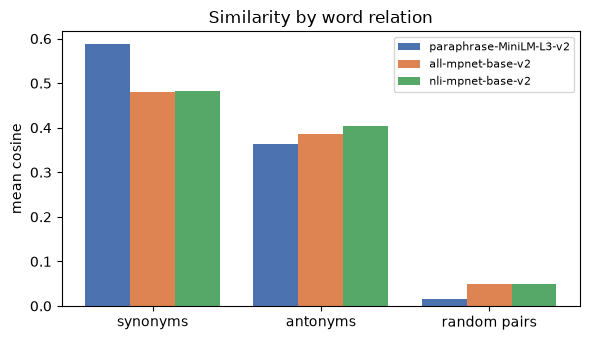

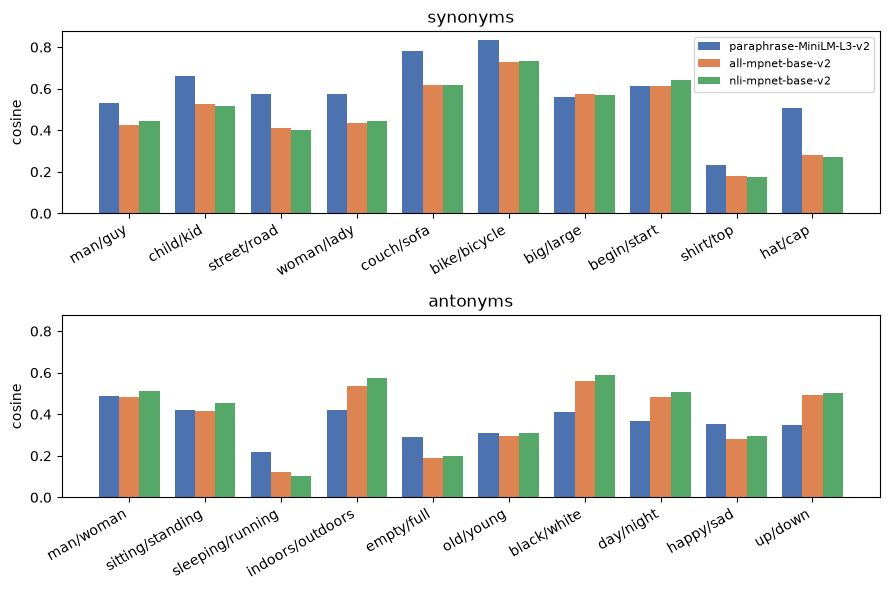

In [12]:
SYNONYMS = [
    ("man", "guy"),
    ("child", "kid"),
    ("street", "road"),
    ("woman", "lady"),
    ("couch", "sofa"),
    ("bike", "bicycle"),
    ("big", "large"),
    ("begin", "start"),
    ("shirt", "top"),
    ("hat", "cap"),
]
ANTONYMS = [
    ("man", "woman"),
    ("sitting", "standing"),
    ("sleeping", "running"),
    ("indoors", "outdoors"),
    ("empty", "full"),
    ("old", "young"),
    ("black", "white"),
    ("day", "night"),
    ("happy", "sad"),
    ("up", "down"),
]

per_pair = {}
summary = {}
for m in EmbeddingModels:
    w, tok = tables[m], tokenizers[m]
    per_pair[short[m]] = {
        "synonyms": pair_similarities(SYNONYMS, w, tok),
        "antonyms": pair_similarities(ANTONYMS, w, tok),
    }
    summary[short[m]] = {
        "synonyms": np.mean(per_pair[short[m]]["synonyms"]),
        "antonyms": np.mean(per_pair[short[m]]["antonyms"]),
        "random pairs": random_pair_similarity(w, range(1000, w.shape[0])),
    }

plot_relation_summary(summary, fig_dir / "relation_summary.png")
plot_pair_similarities(per_pair, SYNONYMS, ANTONYMS, fig_dir / "pair_similarities.png")
pd.DataFrame(summary).T.round(3)

## 2.3 Geometry of SNLI concept groups

2-D PCA of words from four concept groups that make up most SNLI scenes. Related words that are contradictions (e.g. `sleeping`/`running`, `inside`/`outside`) land next to each other if the space encodes topic rather than truth-conditional difference.

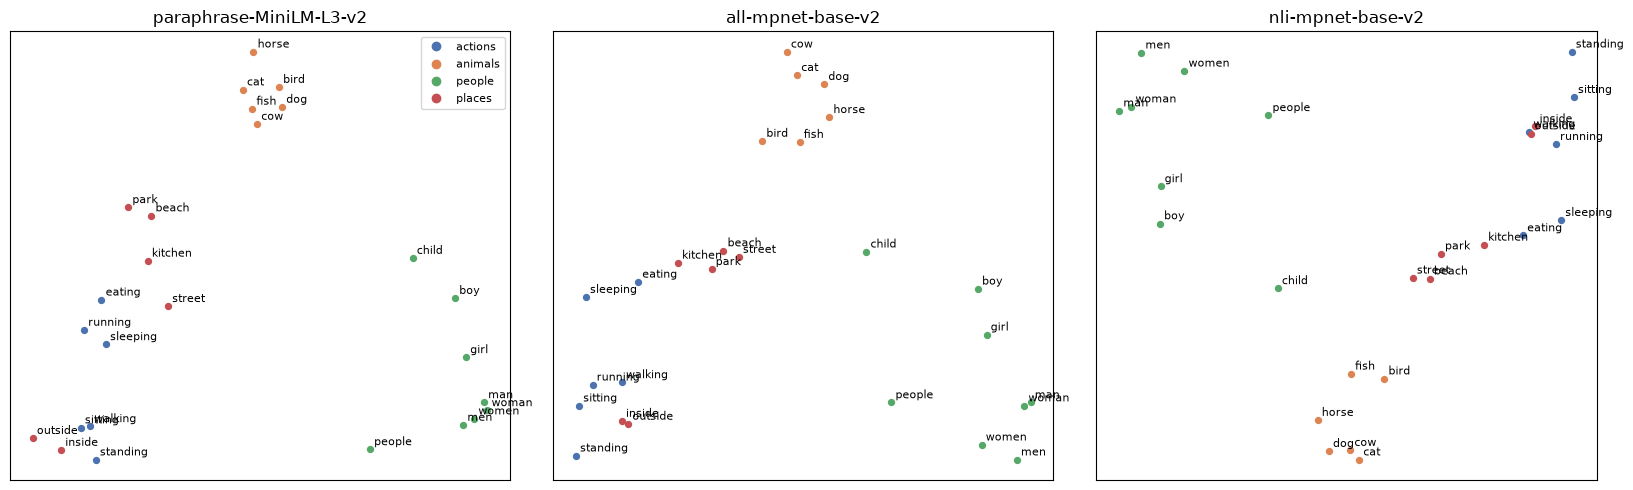

In [13]:
GROUPS = {
    "people": ["man", "woman", "boy", "girl", "child", "men", "women", "people"],
    "animals": ["dog", "cat", "horse", "bird", "cow", "fish"],
    "actions": ["running", "sleeping", "sitting", "standing", "eating", "walking"],
    "places": ["outside", "inside", "beach", "street", "park", "kitchen"],
}
word_group = {w: g for g, words in GROUPS.items() for w in words}
words = list(word_group)

maps = {}
for m in EmbeddingModels:
    vectors = np.stack(
        [word_vector(w, tables[m], tokenizers[m])[0].numpy() for w in words]
    )
    maps[short[m]] = dict(zip(words, pca_2d(vectors)))
plot_word_maps(maps, word_group, fig_dir / "word_maps.png")

## 2.4 Do pooled embeddings separate the NLI classes?

The similarity that matters for our task is premise vs hypothesis. Cosine between mean-pooled premise and hypothesis vectors, by gold label (validation set). If the embedding captured entailment-relevant similarity, entailment pairs should sit to the right of contradiction/neutral ones.

,mean cos (entailment),mean cos (neutral),mean cos (contradiction),AUC entailment vs contradiction
paraphrase-MiniLM-L3-v2,0.798,0.760,0.728,0.698
all-mpnet-base-v2,0.893,0.876,0.864,0.651
nli-mpnet-base-v2,0.877,0.858,0.844,0.651


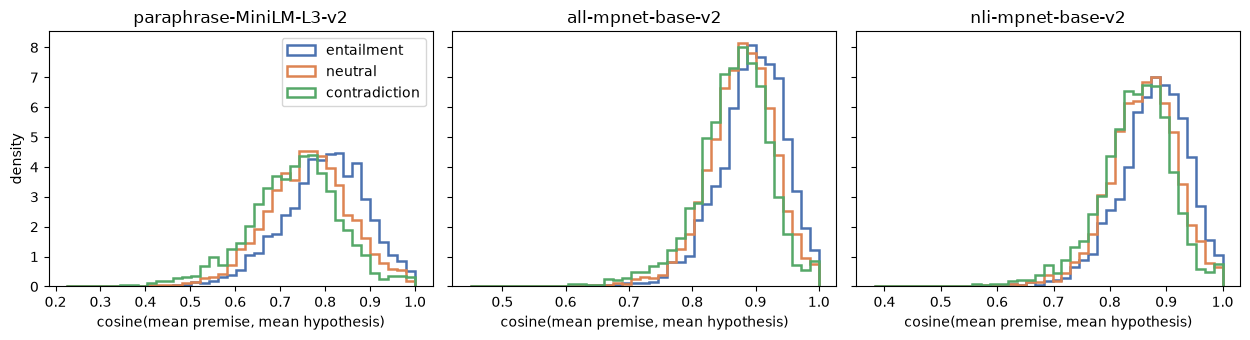

In [14]:
val_labels = val_df[label_col].to_numpy()
cosines = {
    short[m]: pair_cosines(
        val_df[premise_col], val_df[hypothesis_col], tables[m], tokenizers[m], max_length
    )
    for m in EmbeddingModels
}
plot_distribution_by_label(
    cosines,
    val_labels,
    LABEL_NAMES,
    "cosine(mean premise, mean hypothesis)",
    fig_dir / "pair_cosine_by_label.png",
)

ent_vs_con = np.isin(val_labels, [0, 2])
table = pd.DataFrame(
    {
        name: {
            **{f"mean cos ({LABEL_NAMES[k]})": c[val_labels == k].mean() for k in range(3)},
            "AUC entailment vs contradiction": roc_auc_score(
                val_labels[ent_vs_con] == 0, c[ent_vs_con]
            ),
        }
        for name, c in cosines.items()
    }
).T
table.round(3)

## 2.5 Task-specific evidence against alternatives

Frozen mean-pooled embeddings + logistic regression on `[u, v, |u-v|, u*v]`. We compare the candidates with a **random-embedding control** (Gaussian vectors with the MPNet vocabulary and dimension, i.e. no pretraining), repeated over several training subsamples to see variance.

,seed 0,seed 1,seed 2,mean,std
paraphrase-MiniLM-L3-v2,0.6681,0.6632,0.6619,0.6644,0.0033
all-mpnet-base-v2,0.6346,0.6417,0.6441,0.6401,0.0049
nli-mpnet-base-v2,0.6331,0.6434,0.6431,0.6398,0.0058
"random (768d, mpnet vocab)",0.5717,0.5695,0.5727,0.5713,0.0017


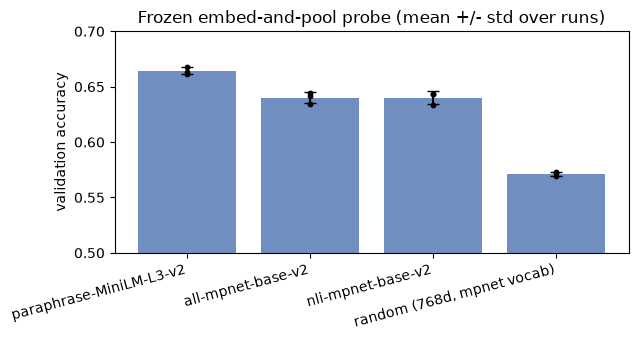

In [15]:
N_TRAIN, SEEDS = 20_000, [0, 1, 2]
rand_table = torch.randn(
    tables[mpnet].shape, generator=torch.Generator().manual_seed(SEED)
)
candidates = {short[m]: (tables[m], tokenizers[m]) for m in EmbeddingModels}
candidates["random (768d, mpnet vocab)"] = (rand_table, tokenizers[mpnet])

scores = {
    name: [
        probe_nli(
            w,
            tok,
            train_df.sample(N_TRAIN, random_state=s),
            val_df,
            max_length,
            s,
        )
        for s in SEEDS
    ]
    for name, (w, tok) in candidates.items()
}
probe = pd.DataFrame(scores).T
probe.columns = [f"seed {s}" for s in SEEDS]
probe["mean"] = probe.mean(axis=1)
probe["std"] = probe[[f"seed {s}" for s in SEEDS]].std(axis=1)
plot_probe(probe, fig_dir / "probe_accuracy.png")
probe.round(4)

## 2.6 Findings and limitations

**What the tables capture**
- Neighbours are morphologically and topically coherent (`dog` -> dogs, puppy, pet, animal; `sleeping` -> slept, sleep, asleep), and the PCA maps cluster people, animals, places and actions.
- Contradictory terms are close: `man` -> woman, `outside` -> inside, `nobody` -> everybody/anybody; `inside`/`outside` almost coincide in the maps. Synonym pairs score higher than antonym pairs on average (MiniLM 0.59 vs 0.36; MPNet ~0.48 vs ~0.39-0.40), but per pair the ranking is not reliable (e.g. `shirt/top` is lower than `black/white`). The table encodes *relatedness* rather than *sameness*.
- nli-mpnet is nearly indistinguishable from all-mpnet: NLI fine-tuning barely moved the static table.
- Premise/hypothesis cosine ranks entailment above neutral above contradiction in all models, but the distributions overlap heavily (AUC entailment vs contradiction 0.65 for the MPNet models, 0.70 for MiniLM). All cosines are high (MPNet ~0.85-0.9) because mean-pooled static vectors share a large common component.

**Task-specific evidence** (frozen mean-pooled embeddings + logistic regression, 20k training pairs, full validation set, 3 subsamples)

| embedding | mean acc. | std |
|---|---|---|
| paraphrase-MiniLM-L3-v2 | 0.664 | 0.003 |
| all-mpnet-base-v2 | 0.640 | 0.005 |
| nli-mpnet-base-v2 | 0.640 | 0.006 |
| random (768d) | 0.571 | 0.002 |

- Pretraining helps: +7 to +9 points over random vectors of the same size and vocabulary.
- all-mpnet and nli-mpnet are tied (difference 0.0003, std ~0.005).
- MiniLM is ~2.4 points better, which is larger than the run-to-run std. Caveat: it has half the dimensions, so the classifier has half as many features to fit from 20k examples. This could be a regularisation effect rather than better embeddings, so we re-check it with the tuned embed-and-pool and GRU models before choosing.
- The random control is far above chance (0.571 vs 0.338) and a model using only surface cues (lexical overlap, lengths, negation; no embeddings) reaches 0.506 (section 3). So much of the signal in this probe is surface structure that even random vectors partly preserve, and pretraining adds the remaining ~7-9 points on top.

**Limitations for NLI**
1. Static token vectors do not model context, negation or word order, which matter for contradiction. Mean pooling also discards order.
2. Distributional similarity places antonyms and mutually exclusive terms close together (man/woman, inside/outside, nobody/everybody), exactly the pairs that signal contradiction in SNLI. The classifier has to learn to separate them.
3. The vocabulary is lower-cased WordPiece. Casing is lost, and 44% of unique words (rare ones, names) are represented by averaged fragments.
4. The input table of a sentence-transformer is not the model: its quality comes from the contextual layers on top, so these tables understate the full model.
5. The probe uses a small subsample, one linear classifier and a single pooling; the ranking of close models may change under tuning. The word lists are small and hand-picked.

# 3. Additional dataset checks

Properties of SNLI itself that determine how far *any* embedding-based classifier can get, and which we need when interpreting later results.

,mean lexical overlap,hypothesis has negation,premise has negation
entailment,0.571,0.007,0.005
neutral,0.422,0.009,0.005
contradiction,0.380,0.048,0.005


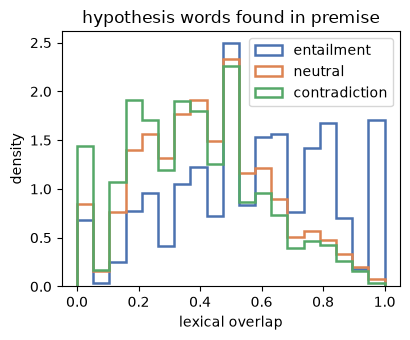

In [16]:
labels = sample_df[label_col].to_numpy()
overlap = lexical_overlap(sample_df[premise_col], sample_df[hypothesis_col])
plot_distribution_by_label(
    {"hypothesis words found in premise": overlap},
    labels,
    LABEL_NAMES,
    "lexical overlap",
    fig_dir / "overlap_by_label.png",
    n_bins=20,
)
neg = {
    part: has_negation(sample_df[col]).astype(float)
    for part, col in [("premise", premise_col), ("hypothesis", hypothesis_col)]
}
pd.DataFrame(
    {
        LABEL_NAMES[k]: {
            "mean lexical overlap": overlap[labels == k].mean(),
            "hypothesis has negation": neg["hypothesis"][labels == k].mean(),
            "premise has negation": neg["premise"][labels == k].mean(),
        }
        for k in range(3)
    }
).T.round(3)

In [17]:
# How far do surface cues alone get (no embeddings at all)? Same training subsamples as the probe.
shallow = [
    shallow_baseline(train_df.sample(N_TRAIN, random_state=s), val_df, s) for s in SEEDS
]
print(f"surface-cue baseline accuracy: {np.mean(shallow):.4f} +/- {np.std(shallow, ddof=1):.4f}")
print(f"chance (majority class): {np.bincount(val_df[label_col]).max() / len(val_df):.4f}")

surface-cue baseline accuracy: 0.5062 +/- 0.0022
chance (majority class): 0.3382


**Interpretation.**
- Lexical overlap is strongly label-dependent: entailment hypotheses reuse 57% of their words from the premise, neutral 42%, contradiction 38%.
- A gradient-boosting model that sees only five surface features (overlap, premise/hypothesis length, negation in each) reaches 0.506 +/- 0.002 validation accuracy (chance 0.338). This is the floor that any embedding-based result should be compared against; random embeddings reach 0.571 and pretrained ones 0.64-0.66, so pretrained meaning adds roughly 13-16 points over surface cues.
- Negation in the *hypothesis* is ~7x more frequent for contradiction (4.8%) than for entailment (0.7%) or neutral (0.9%), a known annotation artifact; premises almost never contain negation (0.5%). A static pooled embedding cannot tell whether a negation applies, so it may exploit the artifact but cannot reason about it.
- Both effects matter for the later error analysis: we should report performance by overlap bucket and by negation presence rather than only overall accuracy.